# Testing Role Classifier
Using the "classify.py" script on the sample dataset to create the full sample dataset

In [1]:
from scripts.classify import JobClassifier
import pandas as pd
from tqdm import tqdm

tqdm.pandas()

## Load Classifier

In [2]:
classifier = JobClassifier(
    taxonomy_path = "data/sample/amended_soc_structure.csv",
    model = "gemma4:e4b-mlx"
)

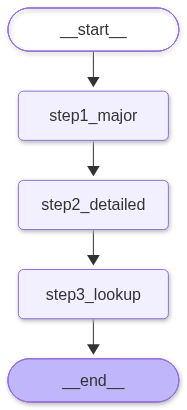

In [3]:
classifier.pipeline

## Load Roles

In [4]:
roles = pd.read_csv("data/sample/roles.csv")
roles.columns = ["Raw Role"]
unique_roles = roles.drop_duplicates()

In [5]:
def classify_role(role_row):
    # classifies a role into our taxonomy

    res = classifier.classify(role_row["Raw Role"])
    return res.__dict__

In [ ]:
classified = unique_roles.progress_apply(classify_role, axis=1, result_type="expand")

  0%|          | 3/7784 [00:03<2:53:05,  1.33s/it]

In [ ]:
classified.to_csv("data/sample/normalized_roles.csv")